# 02 · Results: no tools vs compiler only vs all MCP tools

Same model (gpt-oss-20b on Groq), same 28 tasks, three conditions. Every answer is compiled by us (independent of the agent).
**Faithful fix:** compiles, nothing real removed, only a small change. Scored two ways:
- **v1 (lines):** at most 2 lines changed, none deleted (strict: comments and line breaks count)
- **v2 (tokens):** compares code tokens, ignoring comments and whitespace: at most 4 tokens removed and 15 added
Both are reported; v2 fixes measurement errors found by inspecting the failures (removed comments, joined lines).

## 1. Load and rescore

In [1]:
# Cell 3: Load all results, rescore with the token-based rule, and build one table.
import json, re, difflib                                 # JSONL, tokenizing, comparing token lists
from pathlib import Path                                 # File paths
import pandas as pd                                      # Tables

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # Project folder
tasks = pd.read_json(ROOT / "evals" / "tasks.jsonl", lines=True).set_index("id")   # The 28 tasks (with reference code)
CONDITIONS = ["no_tools", "compiler_only", "all_tools"]
res = pd.concat([pd.read_json(ROOT / "evals" / f"results_{c}.jsonl", lines=True) for c in CONDITIONS], ignore_index=True)

COMMENT_OR_STRING = re.compile(r'//[^\n]*|/\*.*?\*/|@"(?:[^"]|"")*"|"(?:\\.|[^"\\\n])*"', re.DOTALL)   # Comments and strings
TOKEN = re.compile(r'@"(?:[^"]|"")*"|"(?:\\.|[^"\\\n])*"|\'(?:\\.|[^\'\\\n])+\'|@?[A-Za-z_]\w*|\d[\w.]*|\S')   # One C# token


def tokens(code):
    """Code tokens with comments removed (strings are kept intact, even if they contain //)."""
    no_comments = COMMENT_OR_STRING.sub(lambda m: m.group(0) if m.group(0)[0] in '@"' else " ", code)
    return TOKEN.findall(no_comments)


def token_changes(original, pred):
    """(added, removed) tokens between the original and the answer."""
    added = removed = 0
    for op, i1, i2, j1, j2 in difflib.SequenceMatcher(None, tokens(original), tokens(pred), autojunk=False).get_opcodes():
        if op != "equal":
            removed += i2 - i1                           # Tokens taken out (replace counts both sides)
            added += j2 - j1                             # Tokens put in
    return added, removed


rows = []
for r in res.to_dict("records"):
    ref = tasks.loc[r["id"], "fixed"]                    # The original correct code ("" for real tasks)
    if ref:
        added, removed = token_changes(ref, r["final_code"])
        v2 = bool(r["compiles"]) and removed <= 4 and added <= 15
    else:
        added = removed = None
        v2 = bool(r["compiles"])                         # Real tasks: no reference, so "compiles" (checked by hand later)
    rows.append({**r, "faithful_v1": r["faithful"], "faithful_v2": v2, "tok_added": added, "tok_removed": removed})
df = pd.DataFrame(rows)
df["condition"] = pd.Categorical(df["condition"], CONDITIONS, ordered=True)   # Keep the conditions in this order
print(df.groupby("condition", observed=True).size().to_dict())   # Should be 28 each

{'no_tools': 28, 'compiler_only': 28, 'all_tools': 28}


## 2. Headline results

In [2]:
# Cell 5: One row per condition.
summary = df.groupby("condition", observed=True).agg(
    tasks=("id", "size"),
    compiles=("compiles", "mean"),
    faithful_v1=("faithful_v1", "mean"),
    faithful_v2=("faithful_v2", "mean"),
    avg_tool_calls=("n_tool_calls", "mean"),
    avg_tokens=("tokens", "mean"),
    avg_seconds=("seconds", "mean"),
    cut_off=("finish_reason", lambda s: int((s == "length").sum())),        # Ran out of output budget while reasoning
    too_large=("finish_reason", lambda s: int((s == "too_large").sum())))   # Conversation outgrew the request limit
for col in ("compiles", "faithful_v1", "faithful_v2"):
    summary[col] = (summary[col] * 100).round(0).astype(int).astype(str) + "%"
summary[["avg_tool_calls", "avg_tokens", "avg_seconds"]] = summary[["avg_tool_calls", "avg_tokens", "avg_seconds"]].round(1)
summary.to_csv(ROOT / "reports" / "summary.csv")        # For the README
summary

,tasks,compiles,faithful_v1,faithful_v2,avg_tool_calls,avg_tokens,avg_seconds,cut_off,too_large
condition,,,,,,,,,
no_tools,28,79%,68%,64%,0.0,2843.5,14.1,5,0
compiler_only,28,79%,64%,57%,1.9,5945.5,35.7,4,1
all_tools,28,79%,68%,57%,2.6,8043.4,43.9,3,3


## 3. By category (faithful fix v2, %)
Where do the tools help, and where don't they?

condition       no_tools  compiler_only  all_tools   n
category                                              
missing_using       50.0           60.0       50.0  10
real_llm_error       0.0            0.0       25.0   4
syntax             100.0           50.0       50.0   4
wrong_api           90.0           80.0       80.0  10


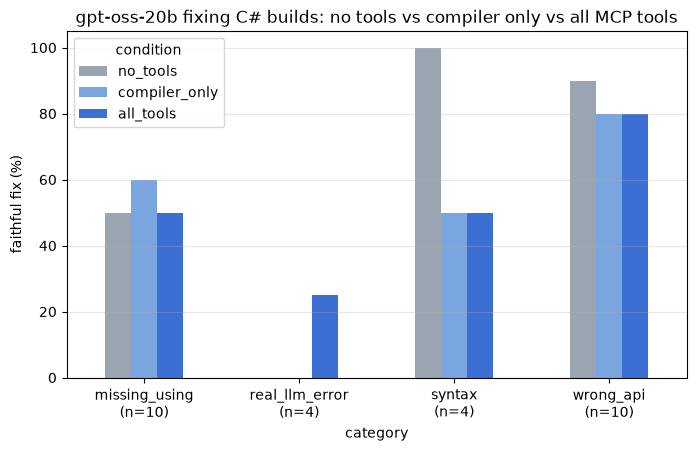

In [3]:
# Cell 7: Success rate per category and condition, plus a chart.
import matplotlib.pyplot as plt                          # Charts

by_cat = df.pivot_table(index="category", columns="condition", values="faithful_v2", aggfunc="mean", observed=True) * 100
by_cat["n"] = df[df["condition"] == "no_tools"].groupby("category").size()   # Tasks per category
print(by_cat.round(0))

ax = by_cat[CONDITIONS].plot.bar(figsize=(8, 4.5), rot=0, color=["#9aa5b1", "#7aa6e0", "#3b6fd4"])
ax.set_ylabel("faithful fix (%)")
ax.set_title("gpt-oss-20b fixing C# builds: no tools vs compiler only vs all MCP tools")
ax.set_xticklabels([f"{c}\n(n={by_cat.loc[c, 'n']})" for c in by_cat.index])
ax.set_ylim(0, 105)
ax.grid(axis="y", alpha=0.3)
plt.savefig(ROOT / "reports" / "results_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Tool usage (all_tools condition)
Which tools did the model call, and did it pick the right tool for the error type?

In [4]:
# Cell 9: How often each tool was called, overall and per category.
at = df[df["condition"] == "all_tools"]
calls = at.explode("tool_calls").dropna(subset=["tool_calls"])   # One row per tool call
print("Calls per tool:", calls["tool_calls"].value_counts().to_dict())
used = pd.DataFrame({tool: at.groupby("category")["tool_calls"].apply(lambda s: s.apply(lambda c: tool in c).mean())
                     for tool in ["find_namespace", "list_members", "compile_csharp", "search_aspnetcore_docs", "fix_compile_errors"]})
print("\nShare of tasks in each category where the tool was used (%):")
print((used * 100).round(0))
print("\nTasks answered without a final compile:", int((~at["tool_calls"].apply(lambda c: "compile_csharp" in c)).sum()))

Calls per tool: {'compile_csharp': 35, 'search_aspnetcore_docs': 16, 'find_namespace': 15, 'list_members': 5, 'fix_compile_errors': 3}

Share of tasks in each category where the tool was used (%):
                find_namespace  list_members  compile_csharp  \
category                                                       
missing_using             60.0          10.0           100.0   
real_llm_error            50.0         100.0            75.0   
syntax                     0.0           0.0           100.0   
wrong_api                 40.0           0.0           100.0   

                search_aspnetcore_docs  fix_compile_errors  
category                                                    
missing_using                     20.0                 0.0  
real_llm_error                   100.0                 0.0  
syntax                             0.0                 0.0  
wrong_api                         20.0                30.0  

Tasks answered without a final compile: 1


## 5. Task by task
Which tasks did each condition get right (v2)? Shows wins and losses, not just averages.

In [5]:
# Cell 11: One row per task, one column per condition (Y = faithful fix v2), plus the finish reasons.
grid = df.pivot_table(index=["category", "id"], columns="condition", values="faithful_v2", aggfunc="first", observed=True)
grid = grid.replace({True: "Y", False: "."})
finish = df.pivot_table(index=["category", "id"], columns="condition", values="finish_reason", aggfunc="first", observed=True)
grid = grid.join(finish.add_suffix("_finish"))
pd.set_option("display.max_rows", 40)
grid

condition                                 no_tools compiler_only all_tools  \
category       id                                                            
missing_using  ex_00771                          .             .         .   
               ex_00949                          Y             Y         Y   
               ex_01067                          Y             Y         Y   
               ex_01421                          .             .         .   
               ex_01742                          Y             Y         Y   
               ex_01917                          Y             Y         Y   
               ex_02323                          .             Y         Y   
               ex_02368                          Y             Y         .   
               ex_02473                          .             .         .   
               ex_02558                          .             .         .   
real_llm_error real/output_cache_baseline        .             .         Y   
               real/output_cache_team            .             .         .   
               real/rate_limit_team              .             .         .   
               real/typed_httpclient_team        .             .         .   
syntax         ex_01432                          Y             Y         .   
               ex_01433                          Y             Y         Y   
               ex_01691                          Y             .         .   
               ex_01692                          Y             .         Y   
wrong_api      ex_00226                          Y             Y         Y   
               ex_01074                          Y             Y         Y   
               ex_01157                          Y             Y         Y   
               ex_01407                          Y             Y         Y   
               ex_01440                          Y             Y         Y   
               ex_01727                          Y             .         .   
               ex_01739                          Y             Y         Y   
               ex_01914                          Y             Y         Y   
               ex_01930                          .             .         .   
               ex_01943                          Y             Y         Y   

condition                                 no_tools_finish  \
category       id                                           
missing_using  ex_00771                            length   
               ex_00949                              stop   
               ex_01067                              stop   
               ex_01421                              stop   
               ex_01742                              stop   
               ex_01917                              stop   
               ex_02323                              stop   
               ex_02368                              stop   
               ex_02473                              stop   
               ex_02558                            length   
real_llm_error real/output_cache_baseline            stop   
               real/output_cache_team              length   
               real/rate_limit_team                length   
               real/typed_httpclient_team          length   
syntax         ex_01432                              stop   
               ex_01433                              stop   
               ex_01691                              stop   
               ex_01692                              stop   
wrong_api      ex_00226                              stop   
               ex_01074                              stop   
               ex_01157                              stop   
               ex_01407                              stop   
               ex_01440                              stop   
               ex_01727                              stop   
               ex_01739                              stop   
            